In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering

from scipy.cluster.hierarchy import dendrogram, linkage

# STEP 1: Load Dataset
df = pd.read_csv(r"C:\Users\HP\Downloads\archive (3)\sales_data_sample.csv", encoding="ISO-8859-1")

print("STEP 1: Original Dataset")
print(df.head())
print("Shape:", df.shape)

STEP 1: Original Dataset
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue 

In [2]:
# STEP 2: Preprocessing

features = ["QUANTITYORDERED", "PRICEEACH", "SALES", "MSRP"]

X = df[features].dropna()

sc = StandardScaler()
X_scaled = sc.fit_transform(X)

print("\nSTEP 2: After Preprocessing")
print("Selected Features:")
print(X.head())

print("Scaled Data Shape:", X_scaled.shape)


STEP 2: After Preprocessing
Selected Features:
   QUANTITYORDERED  PRICEEACH    SALES  MSRP
0               30      95.70  2871.00    95
1               34      81.35  2765.90    95
2               41      94.74  3884.34    95
3               45      83.26  3746.70    95
4               49     100.00  5205.27    95
Scaled Data Shape: (2823, 4)



STEP 3: WCSS Values
[11292.000000000004, 6741.690574808543, 4766.014280081645, 3934.894121194951, 3348.268527079658, 2858.81830618811, 2548.5359725153367, 2350.660048014792, 2169.967218236506, 2019.752998176959]


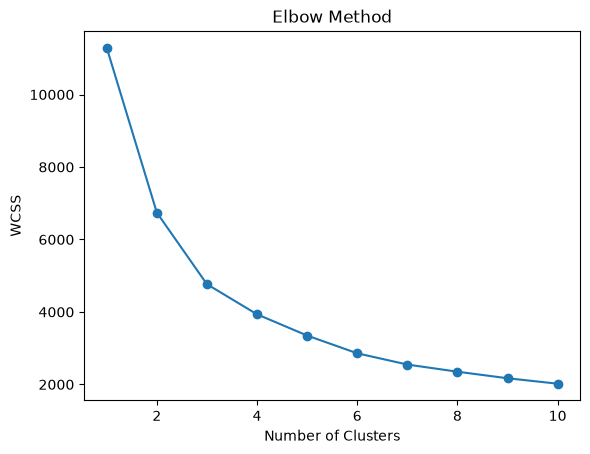

In [3]:
# STEP 3: Elbow Method

wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

print("\nSTEP 3: WCSS Values")
print(wcss)

plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()

In [4]:
# STEP 4: K-Means Clustering

optimal_k = 3

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

df["KMeans_Cluster"] = kmeans_labels

print("\nSTEP 4: K-Means Clustering")
print(df[["SALES", "KMeans_Cluster"]].head())

print("\nCluster Counts:")
print(df["KMeans_Cluster"].value_counts().sort_index())


STEP 4: K-Means Clustering
     SALES  KMeans_Cluster
0  2871.00               2
1  2765.90               2
2  3884.34               1
3  3746.70               1
4  5205.27               1

Cluster Counts:
KMeans_Cluster
0    975
1    852
2    996
Name: count, dtype: int64



STEP 5: Hierarchical Clustering
     SALES  Hierarchical_Cluster
0  2871.00                     2
1  2765.90                     2
2  3884.34                     0
3  3746.70                     0
4  5205.27                     1

Hierarchical Cluster Counts:
Hierarchical_Cluster
0    1204
1     934
2     685
Name: count, dtype: int64


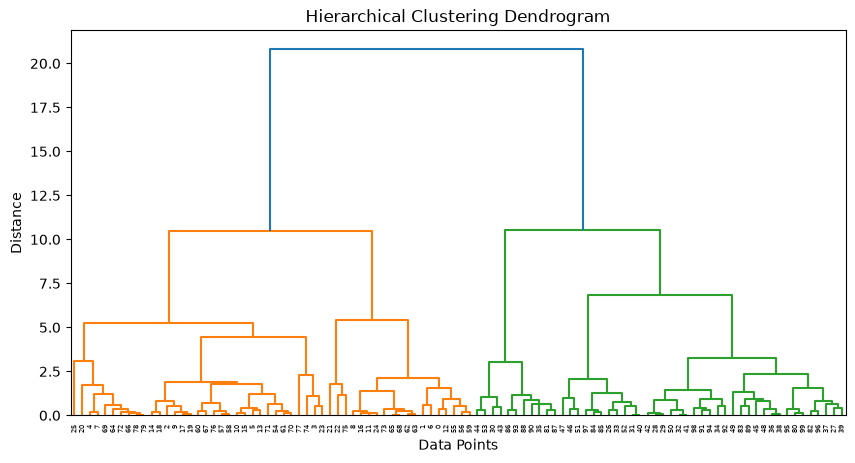

In [5]:
# STEP 5: Hierarchical Clustering

hc = AgglomerativeClustering(n_clusters=optimal_k)

hc_labels = hc.fit_predict(X_scaled)

df["Hierarchical_Cluster"] = hc_labels

print("\nSTEP 5: Hierarchical Clustering")
print(df[["SALES", "Hierarchical_Cluster"]].head())

print("\nHierarchical Cluster Counts:")
print(df["Hierarchical_Cluster"].value_counts().sort_index())

# Dendrogram using a sample of 100 records
sample = X_scaled[:100]

linked = linkage(sample, method="ward")

plt.figure(figsize=(10, 5))
dendrogram(linked)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()